# Week 2: Data Preprocessing & Feature Engineering

## Project: ShopSmart Retail

### Business Objective
Prepare the ShopSmart Retail dataset for machine learning by identifying and addressing data quality issues, engineering meaningful features, encoding categorical variables, scaling numerical features, detecting outliers and selecting relevant features.

### Notebook Workflow
1. Data Inspection
2. Data Cleaning
3. Feature Engineering
4. Feature Encoding and Scaling
5. Outlier Detection and Feature Selection
6. Final Machine Learning-Ready Dataset

## Part 1: Data Inspection

In [1]:
# Importing pandas
import pandas as pd

# Loading the original dataset
df = pd.read_csv("master_dataset.csv")

# Displaying the first 10 rows
df.head(10)

,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Payment_Method,...,Category,Sub_Category,Brand,Cost_Price,Selling_Price,Store_Name,Region,State_store,City_store,Opening_Date
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,...,Groceries,General,Olson-Vance,48631,76491.21,ShopSmart Enugu,South,Enugu,Enugu,2020-05-30
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,...,Home,General,Jones-Vaughn,3269,4909.31,ShopSmart Abuja,North,Abuja,Abuja,2020-10-27
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,...,Electronics,General,"Martinez, Rice and Perry",31027,39852.54,ShopSmart Asaba,South,Delta,Asaba,2020-04-30
3,ORD000004,CUST03536,PROD0051,STR023,2025-07-15,4,69922,5,911,Transfer,...,Home,General,"Peterson, Berry and Cook",29214,50320.76,ShopSmart Abuja,South,Abuja,Abuja,2021-11-21
4,ORD000005,CUST03676,PROD0356,STR021,2025-03-28,5,53344,0,1740,Card,...,Electronics,General,"Sanders, Flores and Lopez",35224,44115.99,ShopSmart Lagos,West,Lagos,Lagos,2021-09-22
5,ORD000006,CUST03203,PROD0458,STR014,2025-03-11,3,31991,0,3452,Card,...,Home,General,Patel-Villanueva,27360,30185.75,ShopSmart Port Harcourt,North,Rivers,Port Harcourt,2021-02-24
6,ORD000007,CUST00082,PROD0174,STR015,2025-09-01,5,5086,20,3064,Card,...,Fashion,General,Smith LLC,36955,54547.93,ShopSmart Lagos,North,Lagos,Lagos,2021-03-26
7,ORD000008,CUST01119,PROD0171,STR019,2025-01-07,4,32902,0,4279,Card,...,Beauty,General,Garcia LLC,33235,59623.71,ShopSmart Kaduna,South,Kaduna,Kaduna,2021-07-24
8,ORD000009,CUST00284,PROD0336,STR015,2025-03-29,2,99649,5,1266,Card,...,Beauty,General,"Miller, Kelly and Adams",21781,26565.82,ShopSmart Lagos,North,Lagos,Lagos,2021-03-26
9,ORD000010,CUST00338,PROD0381,STR017,2025-08-30,4,75235,0,3693,Transfer,...,Fashion,General,"Martin, Haley and Parrish",3951,6032.05,ShopSmart Abuja,South,Abuja,Abuja,2021-05-25


In [2]:
# Examining the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Displaying the complete shape
print("Dataset shape:", df.shape)

Number of rows: 50000
Number of columns: 37
Dataset shape: (50000, 37)


In [3]:
# Reviewing column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           50000 non-null  str    
 1   Customer_ID        50000 non-null  str    
 2   Product_ID         50000 non-null  str    
 3   Store_ID           50000 non-null  str    
 4   Order_Date         50000 non-null  str    
 5   Quantity_order     50000 non-null  int64  
 6   Unit_Price_order   50000 non-null  int64  
 7   Discount_order     50000 non-null  int64  
 8   Shipping_Cost      50000 non-null  int64  
 9   Payment_Method     50000 non-null  str    
 10  Sales_Channel      50000 non-null  str    
 11  Order_Status       50000 non-null  str    
 12  Order_Item_ID      50000 non-null  str    
 13  Line_Total         50000 non-null  int64  
 14  Order_Total        50000 non-null  int64  
 15  Return_Flag        50000 non-null  int64  
 16  First_Name         50000 non-null

In [4]:
#Checking for missing values
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

# Calculating the total number of missing values
print("\nTotal missing values:", missing_values.sum())

Missing values per column:
Order_ID             0
Customer_ID          0
Product_ID           0
Store_ID             0
Order_Date           0
Quantity_order       0
Unit_Price_order     0
Discount_order       0
Shipping_Cost        0
Payment_Method       0
Sales_Channel        0
Order_Status         0
Order_Item_ID        0
Line_Total           0
Order_Total          0
Return_Flag          0
First_Name           0
Last_Name            0
Gender               0
Age                  0
Email                0
Phone                0
City                 0
State                0
Registration_Date    0
Customer_Segment     0
Product_Name         0
Category             0
Sub_Category         0
Brand                0
Cost_Price           0
Selling_Price        0
Store_Name           0
Region               0
State_store          0
City_store           0
Opening_Date         0
dtype: int64

Total missing values: 0


### Missing Value Analysis

The dataset contains 50,000 records and 37 columns. The missing-value check returned zero missing values across all columns.

**Decision:** No missing-value imputation is required at this stage. However, further checks may be needed to identify blank strings or placeholder values that could represent missing information.

In [5]:
# Counting duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Duplicate Record Analysis

The duplicate check identified zero completely duplicated rows in the 50,000-record dataset.

**Decision:** No rows need to be removed for exact full-row duplication. However, identifier uniqueness and other data consistency checks will be examined separately where relevant.

In [6]:
# Generating descriptive statistics for numerical columns
df.describe()

,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Line_Total,Order_Total,Return_Flag,Age,Cost_Price,Selling_Price
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2.99846,50428.605120,9.970600,2747.708600,151505.001720,154252.710320,0.048840,44.067100,25106.672600,36313.194515
std,1.41480,28582.922652,7.086264,1296.187071,119086.335981,119097.398905,0.215536,15.380696,14681.415573,22049.066709
min,1.00000,1003.000000,0.000000,500.000000,993.000000,1753.000000,0.000000,18.000000,535.000000,675.710000
25%,2.00000,25648.750000,5.000000,1628.000000,55957.250000,58692.750000,0.000000,30.000000,11974.000000,16881.490000
50%,3.00000,50631.000000,10.000000,2751.000000,118844.000000,121572.000000,0.000000,44.000000,25025.000000,35927.510000
75%,4.00000,75123.000000,15.000000,3866.000000,225787.750000,228533.250000,0.000000,58.000000,37833.000000,52519.300000
max,5.00000,99998.000000,20.000000,5000.000000,499960.000000,504460.000000,1.000000,70.000000,49949.000000,86152.620000


In [8]:
# Generating descriptive statistics for categorical and text columns
df.describe(include="str").T

,count,unique,top,freq
Order_ID,50000,50000,ORD000001,1
Customer_ID,50000,5000,CUST04474,24
Product_ID,50000,500,PROD0096,132
Store_ID,50000,25,STR015,2064
Order_Date,50000,365,2025-05-14,170
Payment_Method,50000,3,Card,16741
Sales_Channel,50000,2,In-Store,25018
Order_Status,50000,3,Cancelled,16861
Order_Item_ID,50000,50000,OI000001,1
First_Name,50000,595,Michael,1106


### Descriptive Statistics and Initial Observations

The numerical summary showed that the dataset contains 50,000 records. `Quantity_order` ranges from 1 to 5, while `Age` ranges from 18 to 70. `Order_Total` ranges from 1,753 to 504,460 and `Selling_Price` contains decimal values.

The mean of `Return_Flag` is 0.04884, indicating that approximately 4.88% of records are labelled as returns.

The categorical summary showed that `Order_ID` and `Order_Item_ID` each have 50,000 unique values, while `Customer_ID` has 5,000 unique values. The `Sub_Category` column contains only one unique value, `General`.

**Initial preprocessing considerations:**
- Convert date columns to datetime.
- Investigate unusual values in `Phone`.
- Evaluate whether constant and identifier columns are useful for modelling.
- Investigate relationships between monetary variables and the target.
- Assess numerical distributions for potential outliers before deciding on treatment.

In [9]:
# Inspecting the date columns
date_columns = [
    "Order_Date",
    "Registration_Date",
    "Opening_Date"
]

for col in date_columns:
    print(f"\n{col}")
    print(df[col].head())
    print("Data type:", df[col].dtype)

# Inspecting sample phone values
print("\nSample phone values:")
print(df["Phone"].head(20).to_list())

# Checking the constant column
print("\nSub_Category values:")
print(df["Sub_Category"].value_counts())


Order_Date
0    2025-07-19
1    2025-03-15
2    2025-10-01
3    2025-07-15
4    2025-03-28
Name: Order_Date, dtype: str
Data type: str

Registration_Date
0    2023-05-20
1    2024-04-08
2    2025-09-05
3    2024-12-05
4    2024-10-31
Name: Registration_Date, dtype: str
Data type: str

Opening_Date
0    2020-05-30
1    2020-10-27
2    2020-04-30
3    2021-11-21
4    2021-09-22
Name: Opening_Date, dtype: str
Data type: str

Sample phone values:
['+1-468-415-7801x6311', '2185640021', '(370)338-2300x4193', '613.860.9234', '918-256-0682x00286', '329-744-4280', '001-453-662-9003', '737.909.6958x901', '(879)854-8306x87742', '+1-705-633-8190x85253', '205.500.2659', '001-278-293-6769', '(537)622-6680', '846.448.1140', '(394)480-9213x78131', '+1-892-472-0001x901', '482.671.9621x8728', '6334937865', '001-747-950-8467x70226', '544-505-8790']

Sub_Category values:
Sub_Category
General    50000
Name: count, dtype: int64


## Part 2: Data Cleaning

### 2.1 Data Type Corrections

The `Order_Date`, `Registration_Date`, and `Opening_Date` columns contain date values stored as strings. These columns will be converted to datetime format to support date-based analysis and feature engineering.

The `Phone` column contains formatted telephone numbers and will be treated as an identifier rather than a numerical measurement.

The `Sub_Category` column contains a single repeated value and will be considered during feature selection.

In [22]:
# Converting date columns to datetime
# using date_columns list created in the code cell above
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Verifying the updated data types
df[date_columns].info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_Date         50000 non-null  datetime64[us]
 1   Registration_Date  50000 non-null  datetime64[us]
 2   Opening_Date       50000 non-null  datetime64[us]
dtypes: datetime64[us](3)
memory usage: 1.1 MB


In [23]:
# Checking for missing values introduced by date conversion
print(df[date_columns].isna().sum())

# Displaying the updated data types
print(df[date_columns].dtypes)

Order_Date           0
Registration_Date    0
Opening_Date         0
dtype: int64
Order_Date           datetime64[us]
Registration_Date    datetime64[us]
Opening_Date         datetime64[us]
dtype: object


### 2.2 Standerdization of inconsistent values

In [15]:
# Identifying text columns
text_columns = df.select_dtypes(include="str").columns

# Removimg unnecessary spaces from text values
for col in text_columns:
    df[col] = df[col].str.strip()

print("Removed leading and trailing spaces from text columns.")

Removed leading and trailing spaces from text columns.


In [13]:
# Inspectinng unique values in selected categorical columns
categorical_columns = [
    "Payment_Method",
    "Sales_Channel",
    "Order_Status",
    "Gender",
    "Customer_Segment",
    "Category",
    "Region"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique()))


Payment_Method:
['Card', 'Cash', 'Transfer']

Sales_Channel:
['In-Store', 'Online']

Order_Status:
['Cancelled', 'Completed', 'Pending']

Gender:
['Female', 'Male']

Customer_Segment:
['Bronze', 'Gold', 'Silver']

Category:
['Beauty', 'Electronics', 'Fashion', 'Groceries', 'Home']

Region:
['East', 'North', 'South', 'West']


In [14]:
# Checking whether important columns contain unexpected values

print("Order quantity values:")
print(sorted(df["Quantity_order"].unique()))

print("\nDiscount values:")
print(sorted(df["Discount_order"].unique()))

print("\nReturn flag values:")
print(sorted(df["Return_Flag"].unique()))

print("\nOrder status counts:")
print(df["Order_Status"].value_counts())

print("\nSales channel counts:")
print(df["Sales_Channel"].value_counts())

Order quantity values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Discount values:
[np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20)]

Return flag values:
[np.int64(0), np.int64(1)]

Order status counts:
Order_Status
Cancelled    16861
Pending      16610
Completed    16529
Name: count, dtype: int64

Sales channel counts:
Sales_Channel
In-Store    25018
Online      24982
Name: count, dtype: int64


### Text Standardization and Data Type Correction

- Removed leading and trailing spaces from text columns using `.str.strip()`.
- Inspected selected categorical columns and confirmed that their labels had consistent capitalization.
- Converted `Order_Date`, `Registration_Date`, and `Opening_Date` from string values to datetime data types.
- Checked important numerical and categorical columns for unexpected values.
- Confirmed that the dataset contained no missing values or duplicate rows during the initial inspection.

## Part 3: Feature Engineering

### 3.1 Extracting features from Order_Date

In [16]:

# Extracting useful information from the order date

df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Day"] = df["Order_Date"].dt.day
df["Order_DayOfWeek"] = df["Order_Date"].dt.day_name()

# Displaying the new features
df[
    [
        "Order_Date",
        "Order_Year",
        "Order_Month",
        "Order_Day",
        "Order_DayOfWeek"
    ]
].head()


,Order_Date,Order_Year,Order_Month,Order_Day,Order_DayOfWeek
0,2025-07-19,2025,7,19,Saturday
1,2025-03-15,2025,3,15,Saturday
2,2025-10-01,2025,10,1,Wednesday
3,2025-07-15,2025,7,15,Tuesday
4,2025-03-28,2025,3,28,Friday


### 3.2 Creating customer tenure

In [17]:

# Calculating the number of days between registration and order
df["Customer_Tenure_Days"] = (
    df["Order_Date"] - df["Registration_Date"]
).dt.days

# Displaying the results
df[
    [
        "Registration_Date",
        "Order_Date",
        "Customer_Tenure_Days"
    ]
].head()


,Registration_Date,Order_Date,Customer_Tenure_Days
0,2023-05-20,2025-07-19,791
1,2024-04-08,2025-03-15,341
2,2025-09-05,2025-10-01,26
3,2024-12-05,2025-07-15,222
4,2024-10-31,2025-03-28,148


In [18]:

# Checking whether any orders predate customer registration
negative_tenure = (df["Customer_Tenure_Days"] < 0).sum()

print("Records with negative customer tenure:", negative_tenure)
print("Minimum customer tenure:", df["Customer_Tenure_Days"].min())


Records with negative customer tenure: 5159
Minimum customer tenure: -267


In [24]:

# Displaying 10 records where the order predates customer registration
negative_tenure_records = df[
    df["Customer_Tenure_Days"] < 0
]

negative_tenure_records[
    [
        "Customer_ID",
        "Order_Date",
        "Registration_Date",
        "Customer_Tenure_Days",
        "Order_Total",
        "Return_Flag"
    ]
].head(10)


,Customer_ID,Order_Date,Registration_Date,Customer_Tenure_Days,Order_Total,Return_Flag
17,CUST00918,2025-03-09,2025-06-29,-112,236240,0
21,CUST04625,2025-01-17,2025-06-12,-146,65918,0
26,CUST00017,2025-01-10,2025-01-16,-6,63827,1
38,CUST03660,2025-05-28,2025-09-17,-112,138290,1
72,CUST00918,2025-02-24,2025-06-29,-125,125378,0
79,CUST01164,2025-01-29,2025-05-27,-118,247820,0
81,CUST00922,2025-04-24,2025-06-02,-39,87914,0
88,CUST04611,2025-02-20,2025-08-25,-186,252322,0
103,CUST02087,2025-02-09,2025-05-01,-81,139075,0
108,CUST00065,2025-04-02,2025-09-10,-161,308081,0


In [25]:

# Preserving the original tenure calculation
# Creating a modelling feature with invalid negative values set to missing
df["Customer_Tenure_Clean"] = df["Customer_Tenure_Days"].where(
    df["Customer_Tenure_Days"] >= 0
)

# Checking how many values are now missing
print(
    "Missing values in cleaned tenure:",
    df["Customer_Tenure_Clean"].isna().sum()
)

# Confirming the minimum valid tenure
print(
    "Minimum valid tenure:",
    df["Customer_Tenure_Clean"].min()
)


Missing values in cleaned tenure: 5159
Minimum valid tenure: 0.0


### 3.3 Combining existing faetures

In [26]:

# Comparing the existing line total with quantity, price, and discount
df[
    [
        "Quantity_order",
        "Unit_Price_order",
        "Discount_order",
        "Line_Total"
    ]
].head(10)


,Quantity_order,Unit_Price_order,Discount_order,Line_Total
0,1,77989,10,77979
1,3,11240,5,33715
2,2,23595,20,47170
3,4,69922,5,279683
4,5,53344,0,266720
5,3,31991,0,95973
6,5,5086,20,25410
7,4,32902,0,131608
8,2,99649,5,199293
9,4,75235,0,300940


In [27]:

# Calculating quantity multiplied by unit price, then subtract discount
df["Test_Line_Total"] = (
    df["Quantity_order"] * df["Unit_Price_order"]
    - df["Discount_order"]
)

# Comparing calculated totals with the recorded line totals
df[
    [
        "Quantity_order",
        "Unit_Price_order",
        "Discount_order",
        "Test_Line_Total",
        "Line_Total"
    ]
].head(10)


,Quantity_order,Unit_Price_order,Discount_order,Test_Line_Total,Line_Total
0,1,77989,10,77979,77979
1,3,11240,5,33715,33715
2,2,23595,20,47170,47170
3,4,69922,5,279683,279683
4,5,53344,0,266720,266720
5,3,31991,0,95973,95973
6,5,5086,20,25410,25410
7,4,32902,0,131608,131608
8,2,99649,5,199293,199293
9,4,75235,0,300940,300940


In [28]:

# Counting records where the calculated and recorded totals match
matches = (
    df["Test_Line_Total"] == df["Line_Total"]
).sum()

print("Matching records:", matches)
print("Non-matching records:", len(df) - matches)


Matching records: 50000
Non-matching records: 0


In [29]:

# Confirming the formula matches the recorded line total
assert (df["Test_Line_Total"] == df["Line_Total"]).all()

print("Formula verified: all calculated line totals match.")

# Removing the temporary testing column
df.drop(columns=["Test_Line_Total"], inplace=True)


Formula verified: all calculated line totals match.


### 3.4 Identifying irrelevant columns

In [30]:

# Inspecting columns that may be irrelevant or redundant
columns_to_review = [
    "Order_ID",
    "Order_Item_ID",
    "Customer_ID",
    "Product_ID",
    "Store_ID",
    "First_Name",
    "Last_Name",
    "Email",
    "Phone",
    "Sub_Category",
    "Order_Total",
    "Return_Flag"
]

print("Columns to review:")
print(df[columns_to_review].head())

print("\nNumber of unique values:")
print(df[columns_to_review].nunique())


Columns to review:
    Order_ID Order_Item_ID Customer_ID Product_ID Store_ID First_Name  \
0  ORD000001      OI000001   CUST04572   PROD0244   STR005    Ricardo   
1  ORD000002      OI000002   CUST04064   PROD0432   STR010     Robert   
2  ORD000003      OI000003   CUST03435   PROD0052   STR004     Justin   
3  ORD000004      OI000004   CUST03536   PROD0051   STR023   Courtney   
4  ORD000005      OI000005   CUST03676   PROD0356   STR021  Stephanie   

  Last_Name                     Email                 Phone Sub_Category  \
0  Andersen  nchristensen@example.net  +1-468-415-7801x6311      General   
1      Hays     rochamary@example.com            2185640021      General   
2    Wilson      cookpaul@example.net    (370)338-2300x4193      General   
3     Smith  conwayangela@example.org          613.860.9234      General   
4     Perez       jmiller@example.com    918-256-0682x00286      General   

   Order_Total  Return_Flag  
0        81812            0  
1        36587           

In [31]:

# Removing the column with only one unique value
df.drop(columns=["Sub_Category"], inplace=True)

print("Sub_Category removed.")
print("Updated dataset shape:", df.shape)


Sub_Category removed.
Updated dataset shape: (50000, 42)


### 3.5 Renaming columns for consistency

In [33]:

# Displaying all current column names
for column in df.columns:
    print(column)


Order_ID
Customer_ID
Product_ID
Store_ID
Order_Date
Quantity_order
Unit_Price_order
Discount_order
Shipping_Cost
Payment_Method
Sales_Channel
Order_Status
Order_Item_ID
Line_Total
Order_Total
Return_Flag
First_Name
Last_Name
Gender
Age
Email
Phone
City
State
Registration_Date
Customer_Segment
Product_Name
Category
Brand
Cost_Price
Selling_Price
Store_Name
Region
State_store
City_store
Opening_Date
Order_Year
Order_Month
Order_Day
Order_DayOfWeek
Customer_Tenure_Days
Customer_Tenure_Clean


Features already have clear names

In [34]:

# Reviewing the engineered features
engineered_features = [
    "Order_Year",
    "Order_Month",
    "Order_Day",
    "Order_DayOfWeek",
    "Customer_Tenure_Days",
    "Customer_Tenure_Clean"
]

print("Engineered features:")
print(df[engineered_features].head())

print("\nDataset shape:", df.shape)
print(
    "\nMissing values in cleaned customer tenure:",
    df["Customer_Tenure_Clean"].isna().sum()
)


Engineered features:
   Order_Year  Order_Month  Order_Day Order_DayOfWeek  Customer_Tenure_Days  \
0        2025            7         19        Saturday                   791   
1        2025            3         15        Saturday                   341   
2        2025           10          1       Wednesday                    26   
3        2025            7         15         Tuesday                   222   
4        2025            3         28          Friday                   148   

   Customer_Tenure_Clean  
0                  791.0  
1                  341.0  
2                   26.0  
3                  222.0  
4                  148.0  

Dataset shape: (50000, 42)

Missing values in cleaned customer tenure: 5159


### Feature Engineering Summary

1. Extracted `Order_Year`, `Order_Month`, `Order_Day`, and `Order_DayOfWeek` from `Order_Date`.
2. Calculated `Customer_Tenure_Days` using the difference between `Order_Date` and `Registration_Date`.
3. Identified 5,159 records with negative customer tenure, indicating possible inconsistencies in the source dates.
4. Created `Customer_Tenure_Clean`, replacing negative tenure values with missing values while retaining the original records.
5. Verified that `Line_Total` equals `(Quantity_order × Unit_Price_order) − Discount_order` for all 50,000 records.
6. Removed `Sub_Category` because it contained only one unique value and therefore provided no variation.

The dataset currently contains 50,000 rows and 42 columns. The original prediction targets, `Order_Total` and `Return_Flag`, have been retained for the separate regression and classification tasks.

## Part 4: Encoding and Scaling

In [35]:

# Selecting categorical features for our initial ML models
categorical_columns = [
    "Customer_Segment",
    "Payment_Method",
    "Sales_Channel",
    "Category",
    "Region"
]

# Checking the unique categories in each column
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())



Customer_Segment:
Customer_Segment
Gold      16961
Silver    16773
Bronze    16266
Name: count, dtype: int64

Payment_Method:
Payment_Method
Card        16741
Cash        16693
Transfer    16566
Name: count, dtype: int64

Sales_Channel:
Sales_Channel
In-Store    25018
Online      24982
Name: count, dtype: int64

Category:
Category
Beauty         11809
Groceries      10352
Electronics     9969
Fashion         9260
Home            8610
Name: count, dtype: int64

Region:
Region
South    15917
East     14061
North    12027
West      7995
Name: count, dtype: int64


### 4.1 Applying one hot encoding

In [36]:

# Converting categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

# Checking the new dataset shape
print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

# Displaying the newly created columns
new_columns = [
    col for col in df_encoded.columns
    if any(col.startswith(category + "_") for category in categorical_columns)
]

print("\nNew encoded columns:")
print(new_columns)


Original dataset shape: (50000, 42)
Encoded dataset shape: (50000, 54)

New encoded columns:
['Customer_Segment_Bronze', 'Customer_Segment_Gold', 'Customer_Segment_Silver', 'Payment_Method_Card', 'Payment_Method_Cash', 'Payment_Method_Transfer', 'Sales_Channel_In-Store', 'Sales_Channel_Online', 'Category_Beauty', 'Category_Electronics', 'Category_Fashion', 'Category_Groceries', 'Category_Home', 'Region_East', 'Region_North', 'Region_South', 'Region_West']


### 4.2 Scaling Numerical Features

In [37]:

# Select numerical columns in the encoded dataset
numerical_columns = df_encoded.select_dtypes(
    include=["int64", "int32", "float64"]
).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("\nNumerical columns:")
print(numerical_columns)


Number of numerical columns: 32

Numerical columns:
['Quantity_order', 'Unit_Price_order', 'Discount_order', 'Shipping_Cost', 'Line_Total', 'Order_Total', 'Return_Flag', 'Age', 'Cost_Price', 'Selling_Price', 'Order_Year', 'Order_Month', 'Order_Day', 'Customer_Tenure_Days', 'Customer_Tenure_Clean', 'Customer_Segment_Bronze', 'Customer_Segment_Gold', 'Customer_Segment_Silver', 'Payment_Method_Card', 'Payment_Method_Cash', 'Payment_Method_Transfer', 'Sales_Channel_In-Store', 'Sales_Channel_Online', 'Category_Beauty', 'Category_Electronics', 'Category_Fashion', 'Category_Groceries', 'Category_Home', 'Region_East', 'Region_North', 'Region_South', 'Region_West']


In [38]:

from sklearn.preprocessing import StandardScaler

# Numerical features selected for scaling
scaling_columns = [
    "Quantity_order",
    "Unit_Price_order",
    "Discount_order",
    "Shipping_Cost",
    "Age",
    "Cost_Price",
    "Selling_Price",
    "Order_Month",
    "Order_Day",
    "Customer_Tenure_Clean"
]

# Creating the scaler
scaler = StandardScaler()

# Scaling the selected columns
df_scaled = df_encoded.copy()
df_scaled[scaling_columns] = scaler.fit_transform(
    df_scaled[scaling_columns]
)

# Checking the results
print("Original values:")
print(df_encoded[scaling_columns].head())

print("\nScaled values:")
print(df_scaled[scaling_columns].head())


Original values:
   Quantity_order  Unit_Price_order  Discount_order  Shipping_Cost  Age  \
0               1             77989              10           3833   69   
1               3             11240               5           2872   66   
2               2             23595              20            922   22   
3               4             69922               5            911   55   
4               5             53344               0           1740   44   

   Cost_Price  Selling_Price  Order_Month  Order_Day  Customer_Tenure_Clean  
0       48631       76491.21            7         19                  791.0  
1        3269        4909.31            3         15                  341.0  
2       31027       39852.54           10          1                   26.0  
3       29214       50320.76            7         15                  222.0  
4       35224       44115.99            3         28                  148.0  

Scaled values:
   Quantity_order  Unit_Price_order  Discount_or

In [39]:

# Checking the mean and standard deviation after scaling
scaling_summary = df_scaled[scaling_columns].agg(["mean", "std"]).T

print(scaling_summary.round(3))


                       mean  std
Quantity_order         -0.0  1.0
Unit_Price_order       -0.0  1.0
Discount_order          0.0  1.0
Shipping_Cost           0.0  1.0
Age                    -0.0  1.0
Cost_Price             -0.0  1.0
Selling_Price           0.0  1.0
Order_Month             0.0  1.0
Order_Day               0.0  1.0
Customer_Tenure_Clean   0.0  1.0


### Encoding and Scaling Summary

1. Applied one-hot encoding to five categorical features: `Customer_Segment`, `Payment_Method`, `Sales_Channel`, `Category`, and `Region`.
2. The dataset increased from 42 to 54 columns after encoding.
3. Used `StandardScaler` to scale ten selected numerical features so they have comparable scales.
4. Retained the original dataset in `df` and stored the encoded and scaled versions separately in `df_encoded` and `df_scaled`.
5. Excluded `Order_Total` and `Return_Flag` from scaling because they are the prediction targets.
6. Further missing-value handling and training-only fitting of transformations will be addressed during model preparation.

## Part 5: Outlier Detection and Feature Selection

### 5.1 Outlier Detection

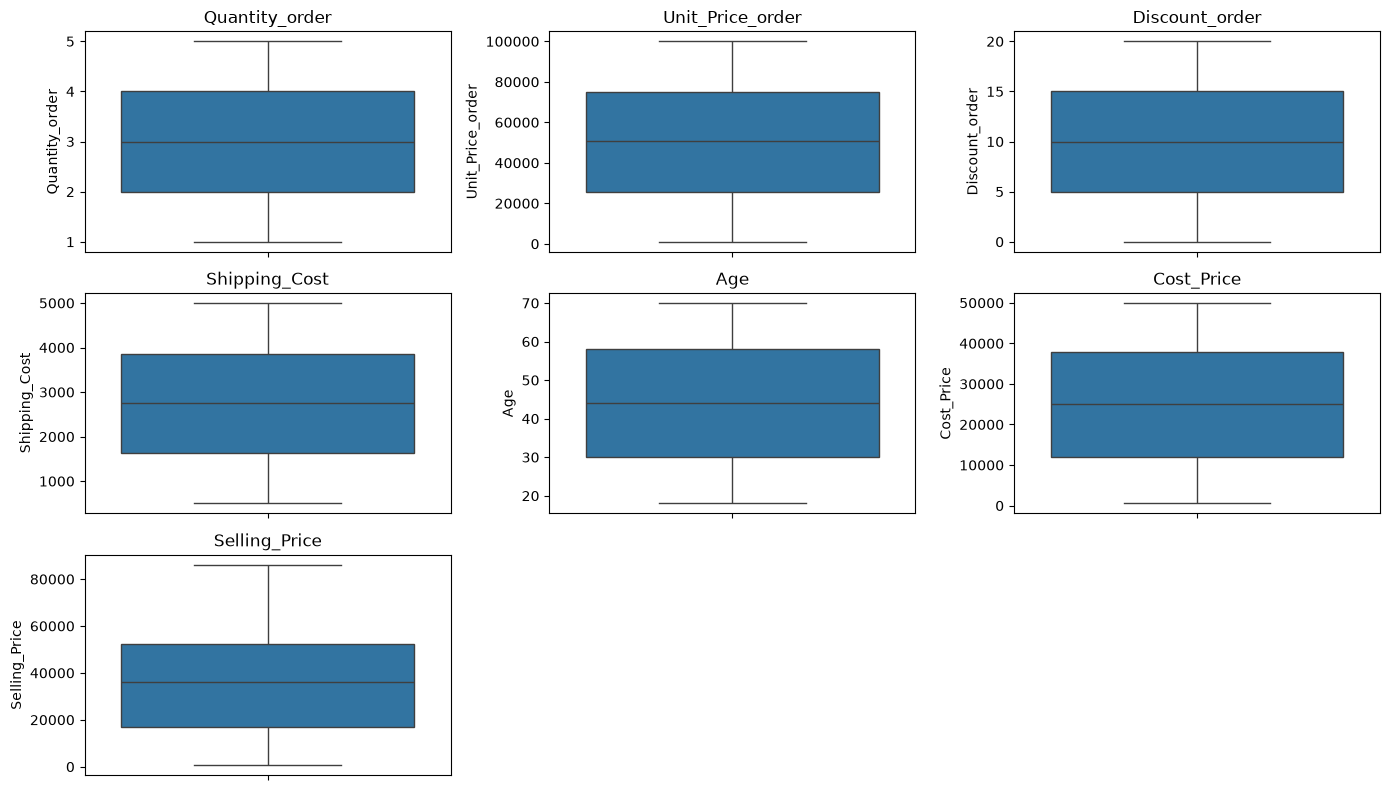

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

# Selecting numerical columns to inspect for outliers
outlier_columns = [
    "Quantity_order",
    "Unit_Price_order",
    "Discount_order",
    "Shipping_Cost",
    "Age",
    "Cost_Price",
    "Selling_Price"
]

# Creating box plots
plt.figure(figsize=(14, 8))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


#### Detecting Outliers using the IQR method

In [41]:

# Detecting potential outliers using the IQR method

outlier_results = []

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    })

# Displaying the results
outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2))


             Column  Lower Limit  Upper Limit  Outlier Count
0    Quantity_order        -1.00         7.00              0
1  Unit_Price_order    -48562.62    149334.38              0
2    Discount_order       -10.00        30.00              0
3     Shipping_Cost     -1729.00      7223.00              0
4               Age       -12.00       100.00              0
5        Cost_Price    -26814.50     76621.50              0
6     Selling_Price    -36575.22    105976.02              0


#### Outlier Detection Summary

1. Visualized seven numerical features using box plots.
2. Applied the Interquartile Range (IQR) method, using 1.5 × IQR to determine the lower and upper limits.
3. Found zero IQR-defined outliers in `Quantity_order`, `Unit_Price_order`, `Discount_order`, `Shipping_Cost`, `Age`, `Cost_Price`, and `Selling_Price`.
4. Retained all observations because no outliers were detected in these selected columns.
5. These results apply only to the seven columns examined; other numerical features may require further investigation.

### 5.2 Feature Selection

In [43]:

# Checking whether Order_Total equals Line_Total plus Shipping_Cost

total_check = (
    df["Line_Total"] + df["Shipping_Cost"]
    == df["Order_Total"]
)

print("Matching records:", total_check.sum())
print("Non-matching records:", (~total_check).sum())


Matching records: 50000
Non-matching records: 0


#### Feature Selection: Target Leakage Check

1. Verified the relationship between `Line_Total`, `Shipping_Cost`, and `Order_Total`.
2. Confirmed that all 50,000 records satisfy `Order_Total = Line_Total + Shipping_Cost`.
3. Identified `Line_Total` and `Shipping_Cost` as direct components of the regression target.
4. These columns will be excluded from the regression model's input features to prevent target leakage.
5. The target column `Order_Total` will be kept separately as the regression target, not used as an input feature.

In [44]:

# Inspecting selected columns for uniqueness and possible redundancy

columns_to_check = [
    "Order_ID",
    "Order_Item_ID",
    "Customer_ID",
    "Product_ID",
    "Store_ID",
    "Order_Date",
    "Order_Year",
    "Order_Month",
    "Order_Day",
    "City",
    "State",
    "State_store",
    "City_store"
]

for col in columns_to_check:
    print(
        f"{col}: {df[col].nunique()} unique values "
        f"out of {len(df)} records"
    )


Order_ID: 50000 unique values out of 50000 records
Order_Item_ID: 50000 unique values out of 50000 records
Customer_ID: 5000 unique values out of 50000 records
Product_ID: 500 unique values out of 50000 records
Store_ID: 25 unique values out of 50000 records
Order_Date: 365 unique values out of 50000 records
Order_Year: 1 unique values out of 50000 records
Order_Month: 12 unique values out of 50000 records
Order_Day: 31 unique values out of 50000 records
City: 10 unique values out of 50000 records
State: 10 unique values out of 50000 records
State_store: 10 unique values out of 50000 records
City_store: 10 unique values out of 50000 records


In [45]:

# Checking whether each customer city maps to only one state
customer_location_check = (
    df.groupby("City")["State"].nunique()
)

# Checking whether each store city maps to only one store state
store_location_check = (
    df.groupby("City_store")["State_store"].nunique()
)

print("States per customer city:")
print(customer_location_check)

print("\nStore states per store city:")
print(store_location_check)


States per customer city:
City
Abeokuta         1
Abuja            1
Asaba            1
Awka             1
Enugu            1
Ibadan           1
Kaduna           1
Kano             1
Lagos            1
Port Harcourt    1
Name: State, dtype: int64

Store states per store city:
City_store
Abeokuta         1
Abuja            1
Asaba            1
Awka             1
Enugu            1
Ibadan           1
Kaduna           1
Kano             1
Lagos            1
Port Harcourt    1
Name: State_store, dtype: int64


In [46]:

# Comparing order status with return flag
status_return_table = pd.crosstab(
    df["Order_Status"],
    df["Return_Flag"],
    margins=True
)

print(status_return_table)

print("\nReturn rate by order status:")
print(
    df.groupby("Order_Status")["Return_Flag"]
    .mean()
    .mul(100)
    .round(2)
)


Return_Flag       0     1    All
Order_Status                    
Cancelled     16045   816  16861
Completed     15731   798  16529
Pending       15782   828  16610
All           47558  2442  50000

Return rate by order status:
Order_Status
Cancelled    4.84
Completed    4.83
Pending      4.98
Name: Return_Flag, dtype: float64


### Feature Selection Summary

1. Removed `Sub_Category` because it contained only one unique value.
2. Identified `Order_ID` and `Order_Item_ID` as unique identifiers and excluded them from initial model inputs.
3. Identified `Order_Year` as a constant feature because all records belong to the same year.
4. Found that each customer city maps to one state and each store city maps to one store state, indicating overlapping location information.
5. Verified that `Order_Total = Line_Total + Shipping_Cost` for all 50,000 records. These component columns will be excluded from regression inputs to prevent target leakage.
6. Examined `Order_Status` against `Return_Flag`. Return rates were similar across statuses, ranging from 4.83% to 4.98%.
7. Model features will be selected separately for regression and classification. Features that may reveal information unavailable at prediction time will be reviewed carefully.

## Part 6: Machine Learning Ready Dataset

In [47]:

# Checking for missing values in the current dataset
missing_summary = df.isna().sum()

missing_summary = missing_summary[missing_summary > 0]

print("Columns with missing values:")
print(missing_summary)

print("\nTotal missing values:", df.isna().sum().sum())
print("Dataset shape:", df.shape)


Columns with missing values:
Customer_Tenure_Clean    5159
dtype: int64

Total missing values: 5159
Dataset shape: (50000, 42)


### Saving the Processed Dataset

In [48]:

from pathlib import Path

# Creating a separate copy for the processed dataset
df_processed = df.copy()

# Removing Order_Year because it has only one unique value
df_processed.drop(columns=["Order_Year"], inplace=True)

# Saving the processed dataset in the current notebook folder
output_path = Path("shopsmart_processed.csv")
df_processed.to_csv(output_path, index=False)

# Confirming the saved dataset
print("Processed dataset saved to:", output_path.resolve())
print("Dataset shape:", df_processed.shape)
print("Total missing values:", df_processed.isna().sum().sum())
print(
    "Missing cleaned tenure values:",
    df_processed["Customer_Tenure_Clean"].isna().sum()
)


Processed dataset saved to: C:\Users\ADMIN\Desktop\ShopSmart Retail Ltd\Week2 Machine Learning\shopsmart_processed.csv
Dataset shape: (50000, 41)
Total missing values: 5159
Missing cleaned tenure values: 5159


In [49]:

# Reloading the saved CSV to verify it
df_check = pd.read_csv("shopsmart_processed.csv")

print("Reloaded dataset shape:", df_check.shape)
print("\nFirst five rows:")
display(df_check.head())

print("\nMissing values in reloaded dataset:")
print(df_check.isna().sum()[df_check.isna().sum() > 0])


Reloaded dataset shape: (50000, 41)

First five rows:


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Payment_Method,...,Store_Name,Region,State_store,City_store,Opening_Date,Order_Month,Order_Day,Order_DayOfWeek,Customer_Tenure_Days,Customer_Tenure_Clean
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,...,ShopSmart Enugu,South,Enugu,Enugu,2020-05-30,7,19,Saturday,791,791.0
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,...,ShopSmart Abuja,North,Abuja,Abuja,2020-10-27,3,15,Saturday,341,341.0
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,...,ShopSmart Asaba,South,Delta,Asaba,2020-04-30,10,1,Wednesday,26,26.0
3,ORD000004,CUST03536,PROD0051,STR023,2025-07-15,4,69922,5,911,Transfer,...,ShopSmart Abuja,South,Abuja,Abuja,2021-11-21,7,15,Tuesday,222,222.0
4,ORD000005,CUST03676,PROD0356,STR021,2025-03-28,5,53344,0,1740,Card,...,ShopSmart Lagos,West,Lagos,Lagos,2021-09-22,3,28,Friday,148,148.0



Missing values in reloaded dataset:
Customer_Tenure_Clean    5159
dtype: int64


In [50]:

# Final verification of the processed dataset

print("Rows:", df_check.shape[0])
print("Columns:", df_check.shape[1])
print("Duplicate rows:", df_check.duplicated().sum())
print("Missing values:", df_check.isna().sum().sum())

print("\nColumn names:")
print(df_check.columns.tolist())


Rows: 50000
Columns: 41
Duplicate rows: 0
Missing values: 5159

Column names:
['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date', 'Quantity_order', 'Unit_Price_order', 'Discount_order', 'Shipping_Cost', 'Payment_Method', 'Sales_Channel', 'Order_Status', 'Order_Item_ID', 'Line_Total', 'Order_Total', 'Return_Flag', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment', 'Product_Name', 'Category', 'Brand', 'Cost_Price', 'Selling_Price', 'Store_Name', 'Region', 'State_store', 'City_store', 'Opening_Date', 'Order_Month', 'Order_Day', 'Order_DayOfWeek', 'Customer_Tenure_Days', 'Customer_Tenure_Clean']


## VIsualizations

### Distribution of Order Totals

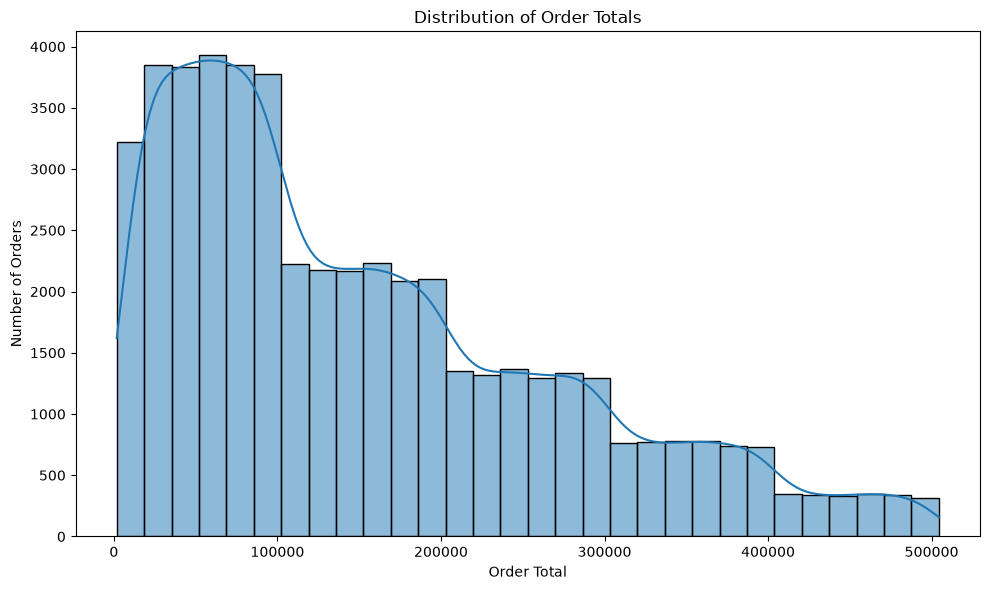

In [52]:
#Had already imported matplotblib and seaborn
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_processed,
    x="Order_Total",
    bins=30,
    kde=True
)

plt.title("Distribution of Order Totals")
plt.xlabel("Order Total")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


**Interpretation:** The distribution of order totals is right-skewed. Most orders are concentrated at lower values, while the frequency of orders decreases as the order total increases. This indicates that lower-value orders are more common, with relatively fewer high-value orders. The distribution should be considered when selecting and evaluating regression models.

### Product Category Distribution

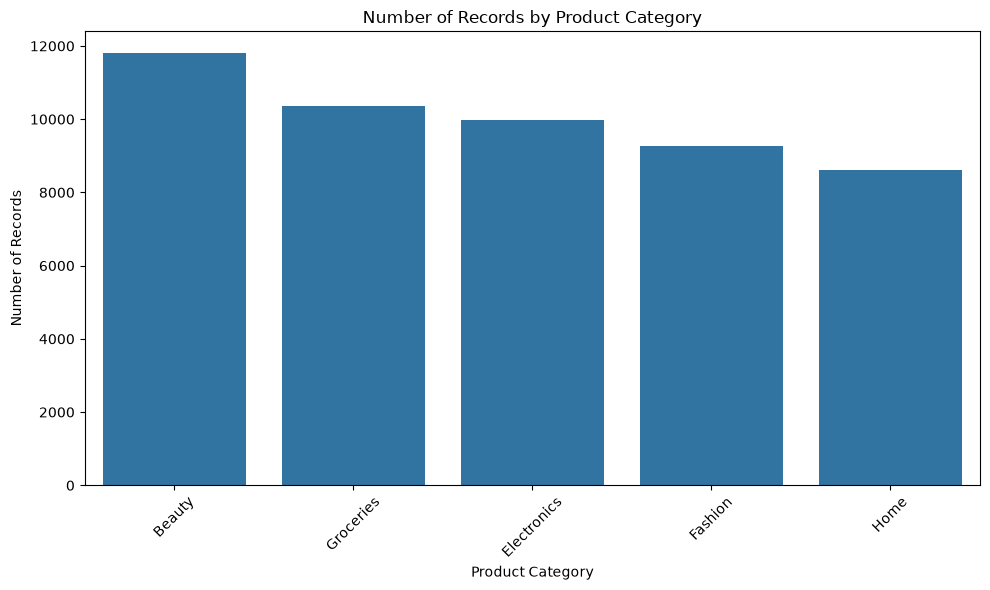

In [53]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_processed,
    x="Category",
    order=df_processed["Category"].value_counts().index
)

plt.title("Number of Records by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Interpretation:** Beauty is the most frequently represented product category, with 11,809 records, while Home has the fewest, with 8,610 records. All five categories have more than 8,000 records, suggesting that the dataset represents a range of product categories without one category accounting for a majority of the records.

### Monthly Order Trend

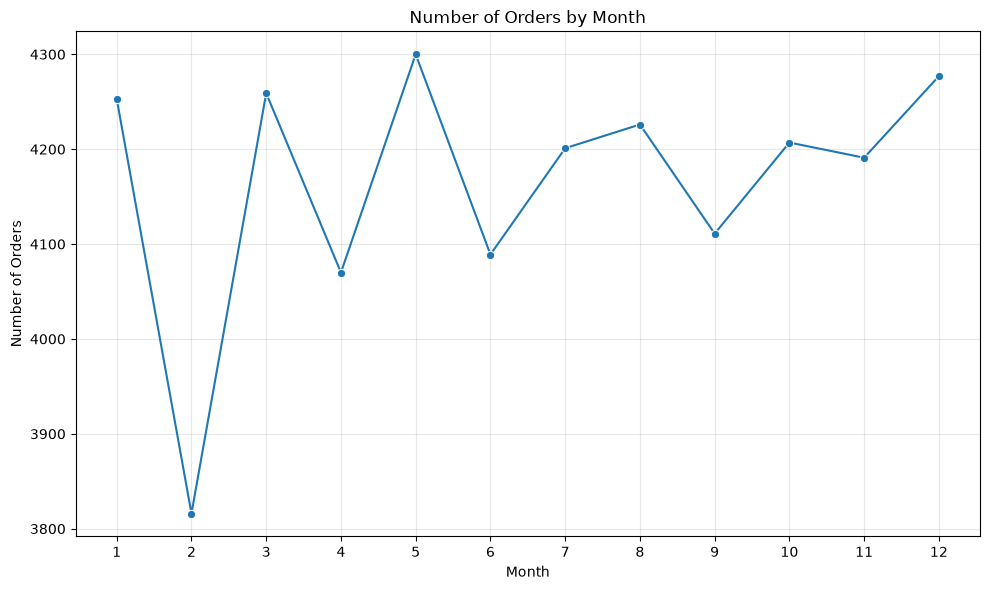

In [54]:

monthly_orders = (
    df_processed.groupby("Order_Month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_orders.index,
    y=monthly_orders.values,
    marker="o"
)

plt.title("Number of Orders by Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** Monthly order counts fluctuate throughout the year rather than following a consistent upward or downward trend. February recorded the fewest orders, at approximately 3,800, while May recorded the most, at approximately 4,300. Most other months recorded around 4,000 or more orders, suggesting relatively steady order activity outside February.

### Numerical Correlation Heatmap

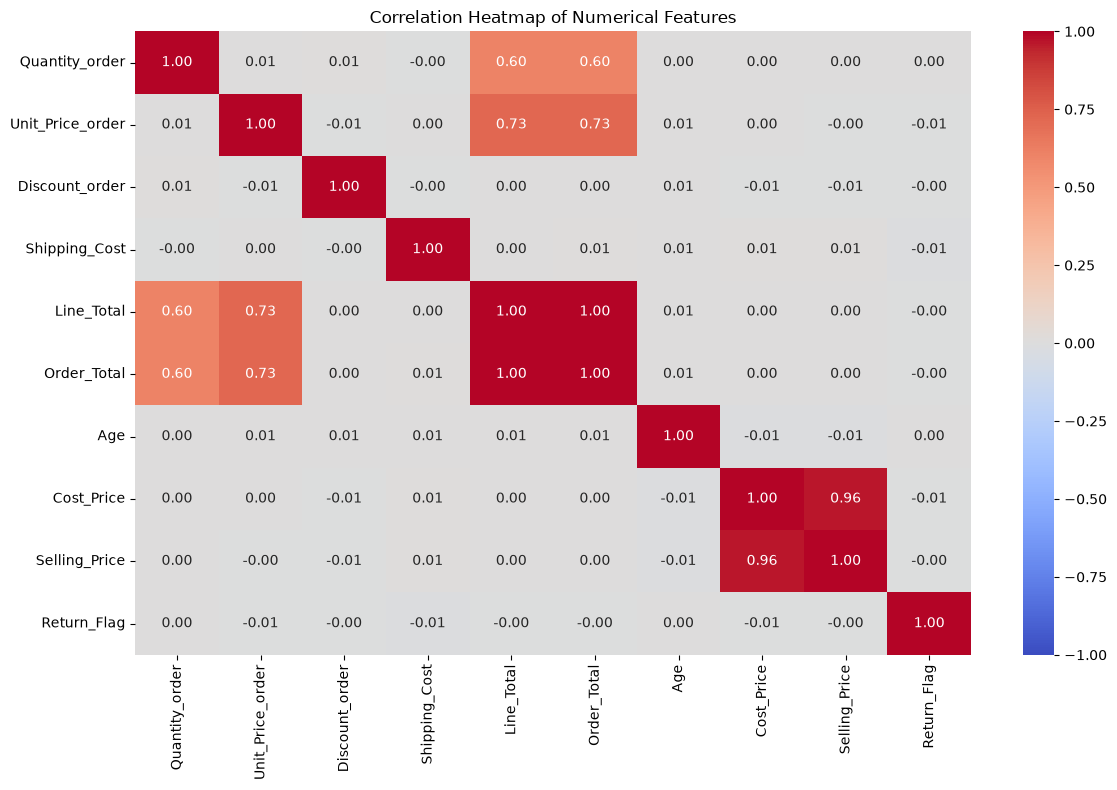

In [55]:

correlation_columns = [
    "Quantity_order",
    "Unit_Price_order",
    "Discount_order",
    "Shipping_Cost",
    "Line_Total",
    "Order_Total",
    "Age",
    "Cost_Price",
    "Selling_Price",
    "Return_Flag"
]

correlation_matrix = df_processed[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


#### Interpretation

The heatmap shows a very strong positive correlation between `Line_Total` and `Order_Total` (approximately 1.00), indicating that the two features have an almost perfect linear relationship. This is expected because `Order_Total` is calculated using `Line_Total` plus `Shipping_Cost`. `Cost_Price` and `Selling_Price` are also strongly positively correlated (0.96).

Both `Line_Total` and `Order_Total` have moderate positive correlations with `Quantity_order` (approximately 0.60) and stronger positive correlations with `Unit_Price_order` (approximately 0.73). Most other pairs of numerical features have correlations close to zero, suggesting weak linear relationships.

`Return_Flag` has little linear correlation with the other numerical features. However, these features may still help predict returns through nonlinear relationships or interactions with other variables.

Correlation does not establish causation. In addition, highly correlated features such as `Line_Total` and `Order_Total` should be considered carefully during feature selection to avoid redundancy and potential target leakage when building machine learning models.

### Order Totals Distribution by Customer Segment

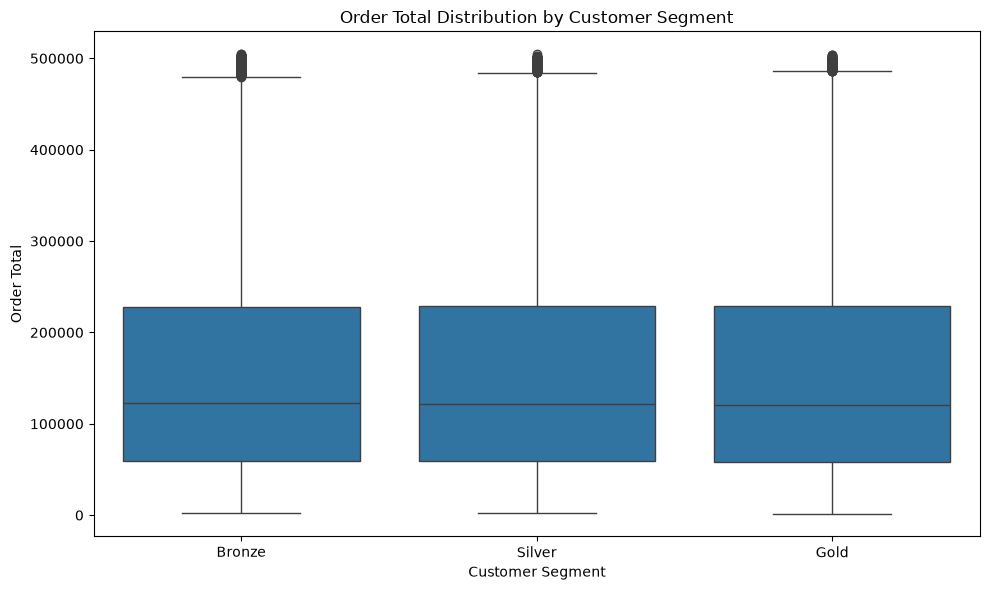

In [56]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_processed,
    x="Customer_Segment",
    y="Order_Total",
    order=["Bronze", "Silver", "Gold"]
)

plt.title("Order Total Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Order Total")
plt.tight_layout()
plt.show()


**Interpretation:** The boxplot compares the distribution of `Order_Total` across Bronze, Silver, and Gold customer segments. The distributions overlap considerably, suggesting that typical order totals may be broadly similar across the three segments. Each segment also shows a wide spread in order values and several high-value outliers, indicating that a small number of orders are substantially larger than most.

Overall, the plot does not show a clear separation in order totals by customer segment. However, further analysis would be needed to determine whether customer segment contributes useful information to a machine learning model.

### Return Rate by Product Category

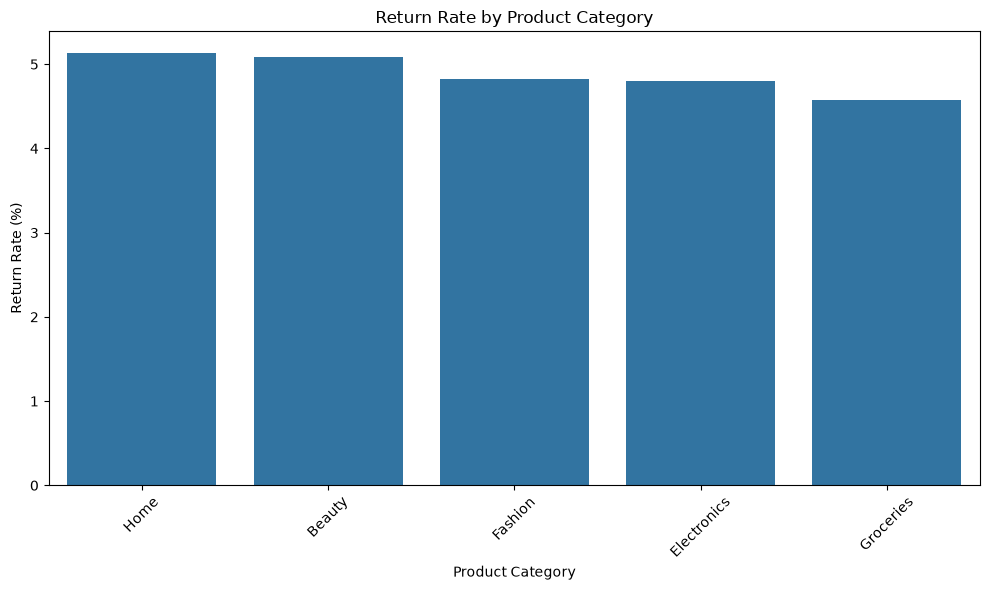

In [57]:

# Calculating the return rate for each product category
return_rates = (
    df_processed.groupby("Category")["Return_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Creating the bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=return_rates.index,
    y=return_rates.values
)

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [58]:

# Calculating return counts and rates by product category for the reports
category_returns = (
    df_processed.groupby("Category")
    .agg(
        Total_Records=("Return_Flag", "count"),
        Returned_Orders=("Return_Flag", "sum"),
        Return_Rate=("Return_Flag", "mean")
    )
)

# Converting return rate to percentage
category_returns["Return_Rate"] = (
    category_returns["Return_Rate"] * 100
)

# Displaying results from highest to lowest return rate
category_returns = category_returns.sort_values(
    by="Return_Rate",
    ascending=False
)

category_returns.round(2)


,Total_Records,Returned_Orders,Return_Rate
Category,,,
Home,8610,442,5.13
Beauty,11809,600,5.08
Fashion,9260,447,4.83
Electronics,9969,479,4.80
Groceries,10352,474,4.58


**Interpretation:** The bar chart compares return rates across the five product categories. Home has the highest return rate at 5.13%, followed closely by Beauty at 5.08%. Fashion and Electronics have return rates of 4.83% and 4.80%, respectively, while Groceries has the lowest rate at 4.58%.

The difference between the highest and lowest return rates is 0.55 percentage points, indicating that return rates are relatively similar across categories. Home and Beauty may warrant further investigation to identify possible factors associated with their slightly higher return rates. However, these results show an association rather than a causal relationship, and further analysis would be needed to determine whether the differences are meaningful.